# Basic CNN for MRI Classification

Implement the specified five-block convolutional network and evaluate four-class MRI image classification.

Completed as part of my Deep Learning coursework. The notebook combines implementation, experiments, results, and the concepts explored.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

PALETTE = ['#2563eb', '#0891b2', '#ea580c', '#7c3aed', '#16a34a']
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titleweight': 'bold',
                     'axes.labelsize': 10, 'font.size': 10})

def show_architecture(stages, title):
    """Draw a compact network/data-flow diagram with readable layer dimensions."""
    columns = min(4, len(stages))
    rows = (len(stages) + columns - 1) // columns
    fig, ax = plt.subplots(figsize=(12, 2.1 * rows))
    ax.set_xlim(-.2, columns * 3); ax.set_ylim(-.2, rows * 2)
    ax.axis('off')
    centers=[]
    for i, label in enumerate(stages):
        row,col=divmod(i,columns)
        if row % 2: col=columns-1-col
        x=col*3; y=(rows-1-row)*2+.3
        box=FancyBboxPatch((x,y),2.4,1.25,boxstyle='round,pad=0.12',
                           facecolor=PALETTE[i%len(PALETTE)],edgecolor='none',alpha=.94)
        ax.add_patch(box)
        ax.text(x+1.2,y+.625,label,ha='center',va='center',color='white',fontsize=10)
        centers.append((x+1.2,y+.625))
    for (x1,y1),(x2,y2) in zip(centers,centers[1:]):
        if y1==y2:
            direction=1 if x2>x1 else -1
            start=(x1+direction*1.35,y1); end=(x2-direction*1.35,y2)
        else: start=(x1,y1-.75); end=(x2,y2+.75)
        ax.annotate('',xy=end,xytext=start,arrowprops={'arrowstyle':'->','color':'#475569','lw':1.8})
    ax.set_title(title,pad=12)
    plt.tight_layout(); plt.show()

## Model overview

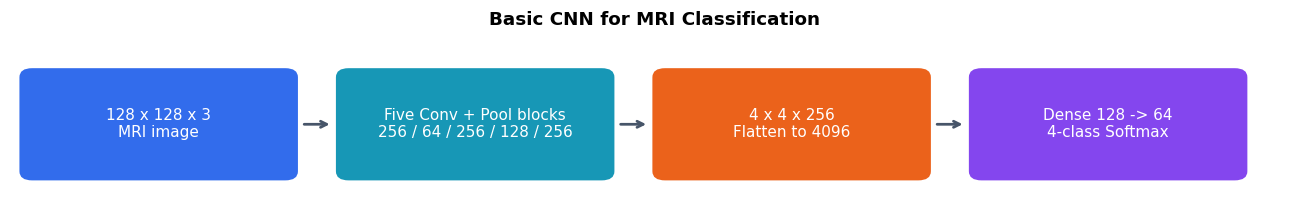

In [2]:
show_architecture(['128 x 128 x 3\nMRI image', 'Five Conv + Pool blocks\n256 / 64 / 256 / 128 / 256', '4 x 4 x 256\nFlatten to 4096', 'Dense 128 -> 64\n4-class Softmax'], 'Basic CNN for MRI Classification')

## Optimization and evaluation

The repeated experiment uses He initialization for ReLU layers and a smaller Adam learning rate after the original networks failed to learn. A small training-only diagnostic guided these changes; it was not a test-set evaluation. Learning rate decreases when validation loss stalls. All variants use the same stratified partitions and batch size. Training runs for 50 epochs, and the checkpoint with the lowest validation loss is used for final evaluation.

## Given architecture
The assignment specifies five convolution + max-pooling blocks, followed by Flatten, Dense(128), Dropout(0.2), Dense(64) and a 4-class Softmax output. I use `padding="same"` so the convolution keeps height/width unchanged before each 2x2 pooling operation.

## Reproducibility and data pipeline

TensorFlow: 2.20.0
Available GPUs: 2


Found 8192 validated image filenames belonging to 4 classes.


Found 8192 validated image filenames belonging to 4 classes.


Found 2048 validated image filenames belonging to 4 classes.


Found 1279 validated image filenames belonging to 4 classes.


Class indices: {'Mild Impairment': 0, 'Moderate Impairment': 1, 'No Impairment': 2, 'Very Mild Impairment': 3}


,train,validation,test
label,,,
Mild Impairment,2048,512,179
Moderate Impairment,2048,512,12
No Impairment,2048,512,640
Very Mild Impairment,2048,512,448


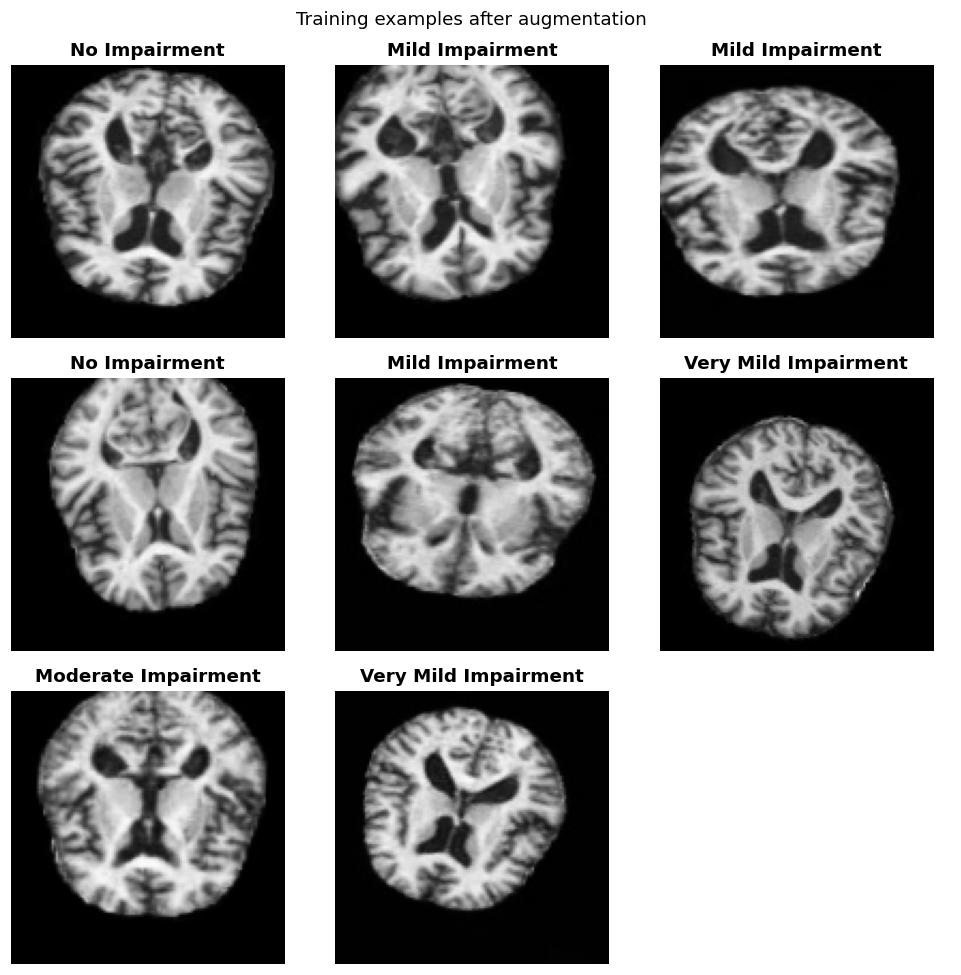

In [3]:
from pathlib import Path
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
tf.config.threading.set_intra_op_parallelism_threads(2)
tf.config.threading.set_inter_op_parallelism_threads(2)
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
IMG_SIZE = (128, 128)
BATCH_SIZE = 8  # Shared across all three architectures for comparison.
EPOCHS = 50
NUM_CLASSES = 4
CLASS_NAMES = ['Mild Impairment', 'Moderate Impairment', 'No Impairment', 'Very Mild Impairment']
DATASET_SLUG = 'lukechugh/best-alzheimer-mri-dataset-99-accuracy'

# Read the attached MRI dataset.
DATA_ROOT = Path('/kaggle/input')
if not DATA_ROOT.is_dir():
    raise FileNotFoundError('The MRI dataset must be attached to this experiment.')
if not tf.config.list_physical_devices('GPU'):
    raise RuntimeError('This full CNN training experiment requires a GPU runtime.')
for gpu in tf.config.list_physical_devices('GPU'):
    tf.config.experimental.set_memory_growth(gpu, True)
print("TensorFlow:", tf.__version__)
print("Available GPUs:", len(tf.config.list_physical_devices('GPU')))


def norm_name(name):
    return ''.join(ch.lower() for ch in name if ch.isalnum())


def class_directories(root):
    names = {norm_name(p.name): p for p in Path(root).iterdir() if p.is_dir()}
    if all(norm_name(name) in names for name in CLASS_NAMES):
        return {name: names[norm_name(name)] for name in CLASS_NAMES}
    return None


def discover_roots(root):
    candidates = []
    for directory, _, _ in os.walk(root):
        if class_directories(directory):
            candidates.append(Path(directory))
    train = [p for p in candidates if norm_name(p.name) in {'train', 'training'}]
    test = [p for p in candidates if norm_name(p.name) in {'test', 'testing'}]
    if len(train) == len(test) == 1:
        return train[0], test[0]
    if len(candidates) == 1:
        return candidates[0], None
    raise ValueError("Ambiguous class-folder layout. Set DATA_ROOT to one dataset "
                     "containing train/test folders or a single class-folder root.")


def image_manifest(root):
    rows = []
    for label, directory in class_directories(root).items():
        paths = sorted(p for p in directory.rglob('*')
                       if p.suffix.lower() in {'.png', '.jpg', '.jpeg', '.bmp', '.tif', '.tiff'}
                       and p.is_file())
        rows.extend({'filename': str(p.resolve()), 'label': label} for p in paths)
    frame = pd.DataFrame(rows)
    if frame.empty or set(frame.label) != set(CLASS_NAMES):
        raise ValueError("Every class must contain supported image files.")
    return frame


TRAIN_ROOT, TEST_ROOT = discover_roots(DATA_ROOT)
train_pool = image_manifest(TRAIN_ROOT)
if TEST_ROOT:
    test_frame = image_manifest(TEST_ROOT)
else:
    # Reserve a genuine held-out test set before constructing validation data.
    train_pool, test_frame = train_test_split(
        train_pool, test_size=0.20, stratify=train_pool.label, random_state=SEED
    )
train_frame, val_frame = train_test_split(
    train_pool, test_size=0.20, stratify=train_pool.label, random_state=SEED
)

AUGMENTATION = dict(rescale=1./255, rotation_range=20, width_shift_range=0.10,
                    height_shift_range=0.10, shear_range=0.10, zoom_range=0.15,
                    horizontal_flip=True, fill_mode='nearest')
train_datagen = ImageDataGenerator(**AUGMENTATION)
eval_datagen = ImageDataGenerator(rescale=1./255)


def make_generator(frame, datagen, shuffle=False):
    return datagen.flow_from_dataframe(
        frame, x_col='filename', y_col='label', classes=CLASS_NAMES,
        target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode='categorical',
        shuffle=shuffle, seed=SEED
    )


train_gen = make_generator(train_frame, train_datagen, shuffle=True)
train_eval_gen = make_generator(train_frame, eval_datagen)
val_gen = make_generator(val_frame, eval_datagen)
test_gen = make_generator(test_frame, eval_datagen)
assert train_gen.class_indices == val_gen.class_indices == test_gen.class_indices
for left, right in [(train_frame, val_frame), (train_frame, test_frame), (val_frame, test_frame)]:
    assert not set(left.filename) & set(right.filename), "Split paths overlap."
print("Class indices:", train_gen.class_indices)
display(pd.DataFrame({name: frame.label.value_counts().reindex(CLASS_NAMES)
                     for name, frame in [('train', train_frame), ('validation', val_frame), ('test', test_frame)]}))

x_batch, y_batch = next(train_gen)
fig, axes = plt.subplots(3, 3, figsize=(9, 9))
for ax, i in zip(axes.flat, range(9)):
    ax.axis('off')
    if i < len(x_batch):
        ax.imshow(x_batch[i])
        ax.set_title(CLASS_NAMES[int(y_batch[i].argmax())])
fig.suptitle('Training examples after augmentation')
plt.tight_layout()
plt.show()
train_gen.reset()

### Original images by class

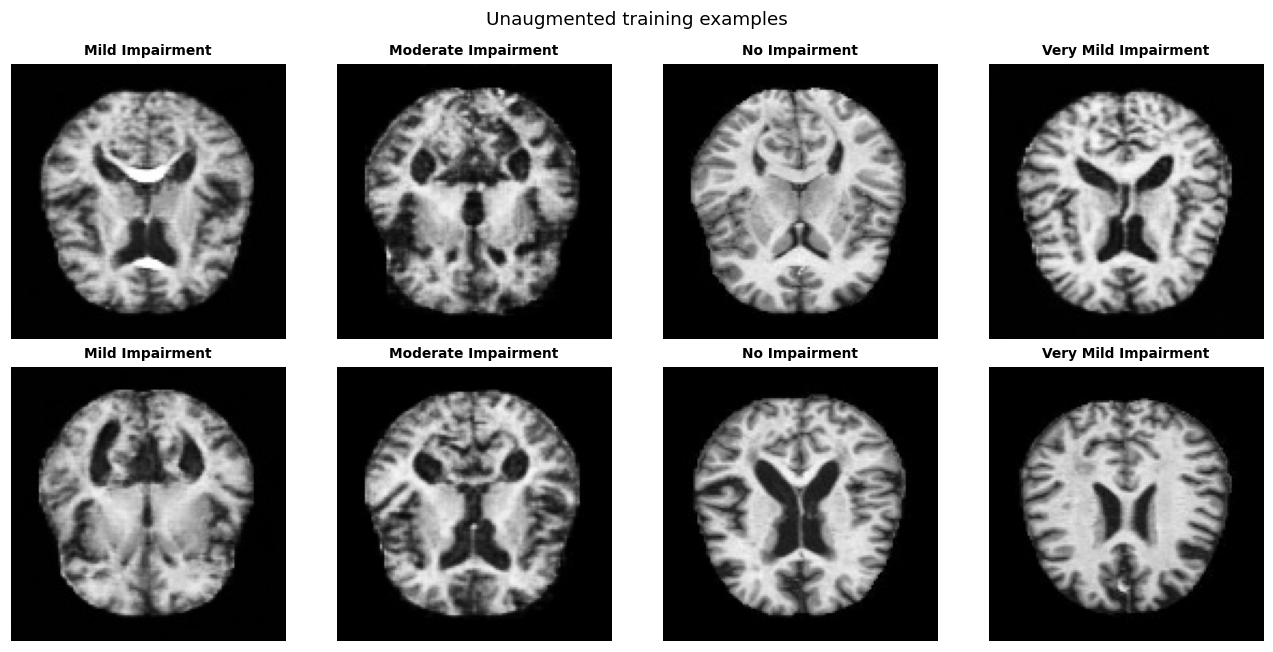

In [4]:
fig,axes=plt.subplots(2,4,figsize=(12,6))
for column,label in enumerate(CLASS_NAMES):
    samples=train_frame[train_frame.label==label].head(2)
    for row,(_,sample) in enumerate(samples.iterrows()):
        axes[row,column].imshow(keras.utils.load_img(sample.filename,target_size=IMG_SIZE))
        axes[row,column].axis('off'); axes[row,column].set_title(label,fontsize=9)
fig.suptitle('Unaugmented training examples'); plt.tight_layout(); plt.show()

## Build and compile the model

In [5]:
# ------------------------------------------------------------
# Build the basic CNN architecture described in the assignment.
# This function creates the convolutional feature extractor and the
# classifier head used for 4-class Alzheimer MRI classification.
# ------------------------------------------------------------
def build_basic_cnn(input_shape=(128, 128, 3), num_classes=4):
    model = keras.Sequential(name='Basic_CNN')
    model.add(layers.Input(shape=input_shape, name='Input'))

    # Block 1: first feature extraction stage with a larger filter bank.
    model.add(layers.Conv2D(256, (3, 3), padding='same', activation='relu', kernel_initializer='he_normal', name='Block1_Conv2D'))
    model.add(layers.MaxPooling2D((2, 2), name='Block1_MaxPool'))

    # Block 2: reduce spatial size while learning mid-level features.
    model.add(layers.Conv2D(64, (3, 3), padding='same', activation='relu', kernel_initializer='he_normal', name='Block2_Conv2D'))
    model.add(layers.MaxPooling2D((2, 2), name='Block2_MaxPool'))

    # Block 3: increase channel depth to capture richer patterns.
    model.add(layers.Conv2D(256, (3, 3), padding='same', activation='relu', kernel_initializer='he_normal', name='Block3_Conv2D'))
    model.add(layers.MaxPooling2D((2, 2), name='Block3_MaxPool'))

    # Block 4: continue extracting discriminative features from the MRI images.
    model.add(layers.Conv2D(128, (3, 3), padding='same', activation='relu', kernel_initializer='he_normal', name='Block4_Conv2D'))
    model.add(layers.MaxPooling2D((2, 2), name='Block4_MaxPool'))

    # Block 5: final convolutional stage before flattening to dense layers.
    model.add(layers.Conv2D(256, (3, 3), padding='same', activation='relu', kernel_initializer='he_normal', name='Block5_Conv2D'))
    model.add(layers.MaxPooling2D((2, 2), name='Block5_MaxPool'))

    # Flatten the 3D feature maps into a vector for the dense classifier.
    model.add(layers.Flatten(name='Flatten'))

    # Dense layers act as the classifier on top of the learned image features.
    model.add(layers.Dense(128, activation='relu', kernel_initializer='he_normal', name='Dense128'))
    model.add(layers.Dropout(0.2, name='Dropout0_2'))
    model.add(layers.Dense(64, activation='relu', kernel_initializer='he_normal', name='Dense64'))

    # Output layer produces 4 probabilities, one per class.
    model.add(layers.Dense(num_classes, activation='softmax', name='Output'))
    return model

# Instantiate the model and compile it for categorical classification.
model = build_basic_cnn()
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=3e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy'], jit_compile=False
)

I0000 00:00:1791697686.969424      19 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791697686.973038      19 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


## Layer dimensions and parameter counts

In [6]:
model.summary()
parameter_summary = pd.DataFrame([
    {'Layer': layer.name, 'Output shape': str(layer.output.shape),
     'Parameters': layer.count_params()} for layer in model.layers
])
display(parameter_summary)
trainable = sum(int(np.prod(weight.shape)) for weight in model.trainable_weights)
non_trainable = sum(int(np.prod(weight.shape)) for weight in model.non_trainable_weights)
print(f'Trainable parameters: {trainable:,}')
print(f'Non-trainable parameters: {non_trainable:,}')
print(f'Total parameters: {model.count_params():,}')
assert trainable + non_trainable == model.count_params()

Model: "Basic_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Block1_Conv2D (Conv2D)          │ (None, 128, 128, 256)  │         7,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Block1_MaxPool (MaxPooling2D)   │ (None, 64, 64, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Block2_Conv2D (Conv2D)          │ (None, 64, 64, 64)     │       147,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Block2_MaxPool (MaxPooling2D)   │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Block3_Conv2D (Conv2D)          │ (None, 32, 32, 256)    │       147,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Block3_MaxPool (MaxPooling2D)   │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Block4_Conv2D (Conv2D)          │ (None, 16, 16, 128)    │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Block4_MaxPool (MaxPooling2D)   │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Block5_Conv2D (Conv2D)          │ (None, 8, 8, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Block5_MaxPool (MaxPooling2D)   │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dense128 (Dense)                │ (None, 128)            │       524,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout0_2 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dense64 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output (Dense)                  │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,425,540 (5.44 MB)

 Trainable params: 1,425,540 (5.44 MB)

 Non-trainable params: 0 (0.00 B)

,Layer,Output shape,Parameters
0,Block1_Conv2D,"(None, 128, 128, 256)",7168
1,Block1_MaxPool,"(None, 64, 64, 256)",0
2,Block2_Conv2D,"(None, 64, 64, 64)",147520
3,Block2_MaxPool,"(None, 32, 32, 64)",0
4,Block3_Conv2D,"(None, 32, 32, 256)",147712
5,Block3_MaxPool,"(None, 16, 16, 256)",0
6,Block4_Conv2D,"(None, 16, 16, 128)",295040
7,Block4_MaxPool,"(None, 8, 8, 128)",0
8,Block5_Conv2D,"(None, 8, 8, 256)",295168
9,Block5_MaxPool,"(None, 4, 4, 256)",0


Trainable parameters: 1,425,540
Non-trainable parameters: 0
Total parameters: 1,425,540


### Parameter distribution across layers

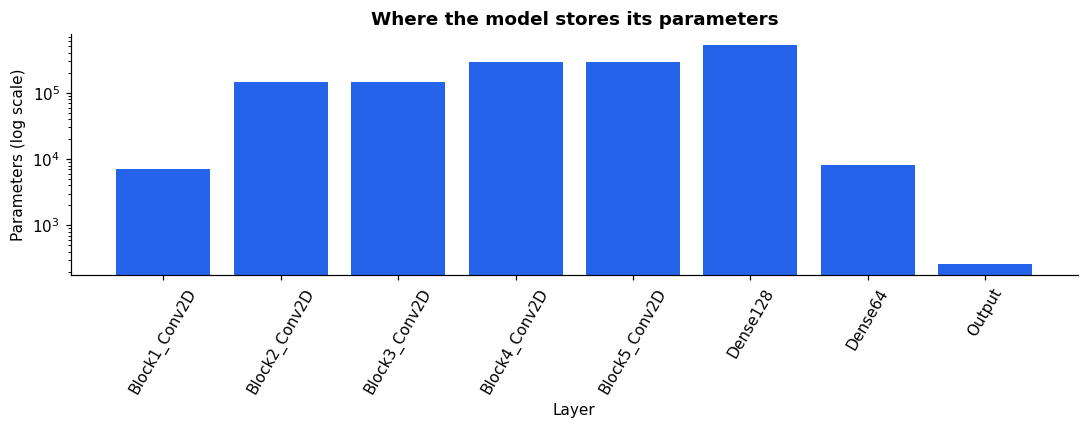

In [7]:
parameter_layers=parameter_summary[parameter_summary['Parameters']>0]
fig,ax=plt.subplots(figsize=(10,4))
ax.bar(parameter_layers['Layer'],parameter_layers['Parameters'],color=PALETTE[0]); ax.set_yscale('log')
ax.set(xlabel='Layer',ylabel='Parameters (log scale)',title='Where the model stores its parameters')
ax.tick_params(axis='x',rotation=60); plt.tight_layout(); plt.show()

### Manual parameter calculation

Each convolution contributes `(kernel height × kernel width × input channels + 1) × output channels`; the extra one represents its bias. Dense layers contribute `input units × output units + output units`.

In [8]:
# Detailed calculation for the specified 128x128x3 input.
# Conv2D params = (kernel_h * kernel_w * input_channels + 1 bias) * filters
# Dense params   = input_units * output_units + output_units bias
# These numbers help confirm the model size and understand the parameter budget.

calculations = [
    ('Conv1', (3*3*3 + 1) * 256),
    ('Conv2', (3*3*256 + 1) * 64),
    ('Conv3', (3*3*64 + 1) * 256),
    ('Conv4', (3*3*256 + 1) * 128),
    ('Conv5', (3*3*128 + 1) * 256),
    ('Dense128', (4*4*256) * 128 + 128),
    ('Dense64', 128 * 64 + 64),
    ('Output', 64 * NUM_CLASSES + NUM_CLASSES),
]

for name, value in calculations:
    print(f'{name:10s}: {value:,}')
print(f'\nTotal learnable parameters: {sum(v for _, v in calculations):,}')
print('Dropout and MaxPooling have 0 learnable parameters.')

Conv1     : 7,168
Conv2     : 147,520
Conv3     : 147,712
Conv4     : 295,040
Conv5     : 295,168
Dense128  : 524,416
Dense64   : 8,256
Output    : 260

Total learnable parameters: 1,425,540
Dropout and MaxPooling have 0 learnable parameters.


## Train for 50 epochs

In [9]:
# Select weights using validation loss, then evaluate the held-out test set once.
checkpoint = Path('artifacts') / (model.name + '_best.weights.h5')
checkpoint.parent.mkdir(exist_ok=True)
callbacks = [
    keras.callbacks.ModelCheckpoint(str(checkpoint), monitor='val_loss', save_best_only=True, save_weights_only=True),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-6)
]
history = model.fit(train_gen, validation_data=val_gen, epochs=EPOCHS,
                    callbacks=callbacks, verbose=2)
best_epoch = int(np.argmin(history.history['val_loss']) + 1)
model.load_weights(checkpoint)
print(f'Restored validation-selected epoch: {best_epoch}')

Epoch 1/50


1024/1024 - 69s - 67ms/step - accuracy: 0.4680 - loss: 1.1327 - val_accuracy: 0.6250 - val_loss: 0.7851 - learning_rate: 3.0000e-04


Epoch 2/50


1024/1024 - 44s - 43ms/step - accuracy: 0.6459 - loss: 0.7379 - val_accuracy: 0.6660 - val_loss: 0.6865 - learning_rate: 3.0000e-04


Epoch 3/50


...

Epoch 49/50


1024/1024 - 43s - 42ms/step - accuracy: 0.8628 - loss: 0.2988 - val_accuracy: 0.8472 - val_loss: 0.3621 - learning_rate: 9.3750e-06


Epoch 50/50


1024/1024 - 41s - 40ms/step - accuracy: 0.8606 - loss: 0.3020 - val_accuracy: 0.8394 - val_loss: 0.3756 - learning_rate: 9.3750e-06


Restored validation-selected epoch: 37


## Training and validation curves

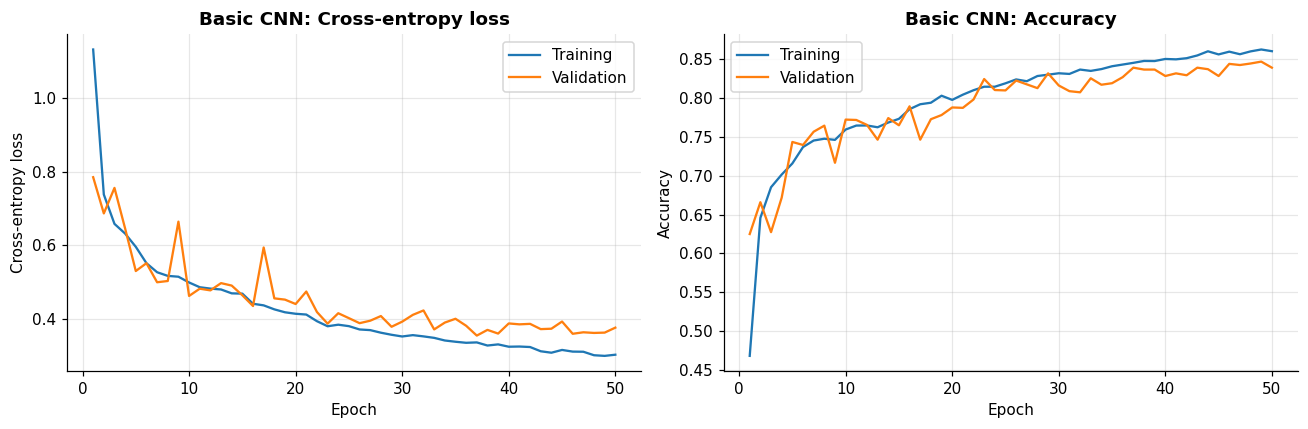

In [10]:
def plot_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    epochs = range(1, len(history.history['loss']) + 1)
    for ax, key, label in zip(axes, ['loss', 'accuracy'], ['Cross-entropy loss', 'Accuracy']):
        ax.plot(epochs, history.history[key], label='Training')
        ax.plot(epochs, history.history['val_' + key], label='Validation')
        ax.set(xlabel='Epoch', ylabel=label, title=f'{title}: {label}')
        ax.grid(alpha=0.3)
        ax.legend()
    plt.tight_layout()
    plt.show()

plot_history(history, 'Basic CNN')

## Final training and test evaluation

Training accuracy without augmentation: 85.62%


Basic CNN: test loss = 0.6473, test accuracy = 70.84%
                      precision    recall  f1-score   support

     Mild Impairment     0.6416    0.6201    0.6307       179
 Moderate Impairment     1.0000    0.8333    0.9091        12
       No Impairment     0.7537    0.8031    0.7776       640
Very Mild Impairment     0.6546    0.6049    0.6288       448

            accuracy                         0.7084      1279
           macro avg     0.7625    0.7154    0.7365      1279
        weighted avg     0.7056    0.7084    0.7061      1279



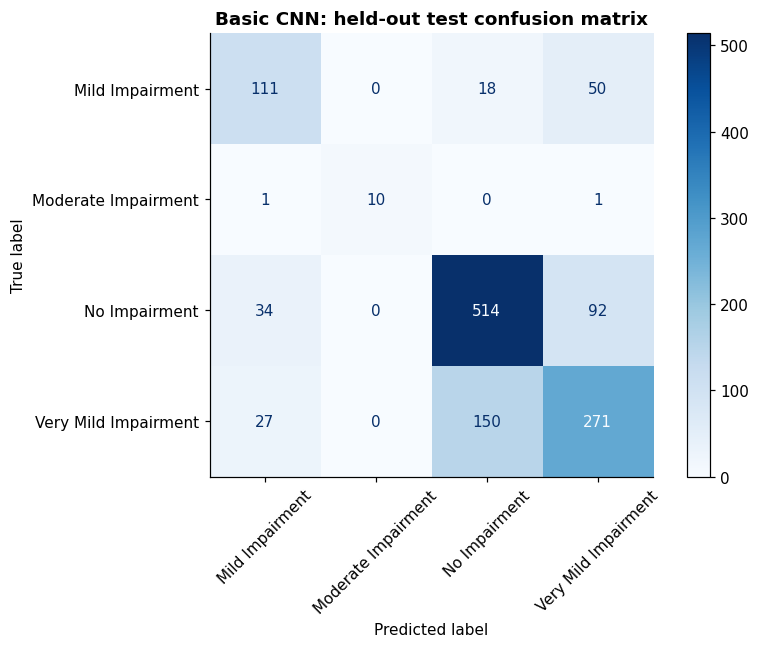

,Model,Train accuracy,Test accuracy,Test loss,Total parameters
0,Basic CNN,0.856201,0.708366,0.647312,1425540


In [11]:
MODEL_TITLE = 'Basic CNN'

def evaluate_and_report(model, generator, title):
    if generator.shuffle:
        raise ValueError("Evaluation predictions must follow the fixed label order.")
    generator.reset()
    loss, accuracy = model.evaluate(generator, verbose=0)
    generator.reset()
    predictions = model.predict(generator, verbose=0).argmax(axis=1)
    labels = np.arange(NUM_CLASSES)
    print(f'{title}: test loss = {loss:.4f}, test accuracy = {accuracy:.2%}')
    print(classification_report(generator.classes, predictions, labels=labels,
                                target_names=CLASS_NAMES, digits=4, zero_division=0))
    cm = confusion_matrix(generator.classes, predictions, labels=labels)
    fig, ax = plt.subplots(figsize=(8, 6))
    ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(
        ax=ax, cmap='Blues', xticks_rotation=45
    )
    ax.set_title(f'{title}: held-out test confusion matrix')
    plt.tight_layout()
    plt.show()
    return loss, accuracy, cm

train_eval_gen.reset()
train_loss, train_acc = model.evaluate(train_eval_gen, verbose=0)
print(f'Training accuracy without augmentation: {train_acc:.2%}')
test_loss, test_acc, cm = evaluate_and_report(model, test_gen, MODEL_TITLE)
display(pd.DataFrame([{'Model': MODEL_TITLE, 'Train accuracy': train_acc,
                      'Test accuracy': test_acc, 'Test loss': test_loss,
                      'Total parameters': model.count_params()}]))

### Example held-out predictions

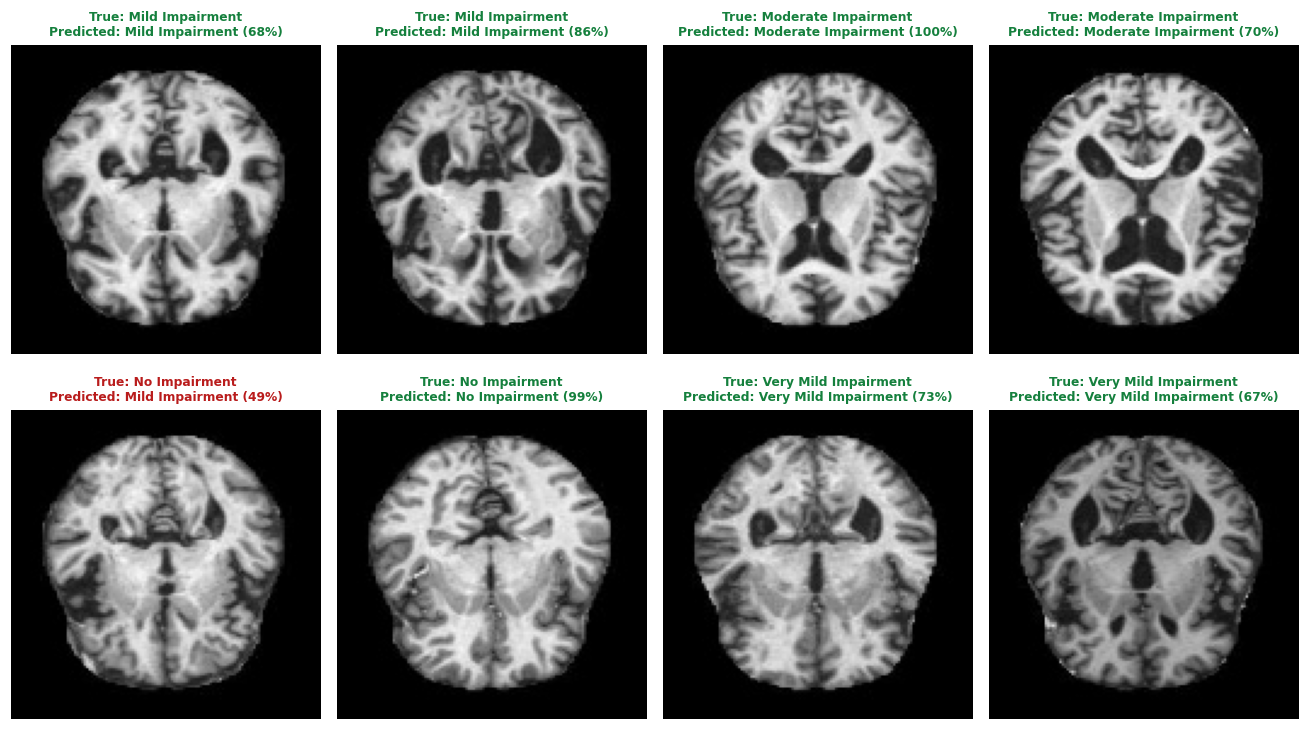

In [12]:
sample_rows=test_frame.groupby('label',sort=False).head(2)
preview=np.asarray([keras.utils.img_to_array(keras.utils.load_img(p,target_size=IMG_SIZE))/255.
                    for p in sample_rows.filename],dtype=np.float32)
probabilities=model.predict(preview,batch_size=BATCH_SIZE,verbose=0)
fig,axes=plt.subplots(2,4,figsize=(12,7))
for ax,image,truth,prob in zip(axes.flat,preview,sample_rows.label,probabilities):
    predicted=CLASS_NAMES[int(prob.argmax())]
    ax.imshow(image); ax.axis('off')
    ax.set_title(f'True: {truth}\nPredicted: {predicted} ({prob.max():.0%})',
                 fontsize=8,color='#15803d' if predicted==truth else '#b91c1c')
plt.tight_layout(); plt.show()

## Interpretation

Compare held-out test accuracy and class-wise precision/recall with the validation curves. Declining training loss alongside rising validation loss suggests overfitting. Evaluate training accuracy without augmentation to obtain a consistent measure on the original training images.

The dataset title includes “99% Accuracy”; that is part of its name, not a measured result of this experiment. Report only metrics from the executed notebook. Image-level separation prevents identical file paths from appearing in multiple partitions, but does not establish patient-level independence or rule out duplicate images under different filenames.

Compare all three variants after completing their runs. The basic architecture uses Flatten; the modified versions use global average pooling. Batch normalization introduces trainable scale/shift parameters and non-trainable running statistics. The BatchNorm variant also adds dropout in convolution blocks, so changes relative to the modified CNN cannot be attributed exclusively to normalization.

In [13]:
# Retain the measured results and learning curves alongside the executed notebook.
import json
metrics = {'model': MODEL_TITLE, 'parameters': model.count_params(),
           'best_validation_epoch': best_epoch, 'training_accuracy': float(train_acc),
           'test_accuracy': float(test_acc), 'test_loss': float(test_loss),
           'confusion_matrix': cm.tolist(),
           'split_sizes': {'train': len(train_frame), 'validation': len(val_frame), 'test': len(test_frame)}}
Path(model.name + '_results.json').write_text(json.dumps(metrics, indent=2))
pd.DataFrame(history.history).to_csv(model.name + '_history.csv', index_label='epoch_index')
display(metrics)

{'model': 'Basic CNN',
 'parameters': 1425540,
 'best_validation_epoch': 37,
 'training_accuracy': 0.856201171875,
 'test_accuracy': 0.7083659172058105,
 'test_loss': 0.6473121047019958,
 'confusion_matrix': [[111, 0, 18, 50],
  [1, 10, 0, 1],
  [34, 0, 514, 92],
  [27, 0, 150, 271]],
 'split_sizes': {'train': 8192, 'validation': 2048, 'test': 1279}}

## Measured findings

The checkpoint selected at epoch **37** achieved **70.84%** test accuracy and **0.7365** macro F1. Training accuracy on unaugmented images was **85.62%**. The provided test set is imbalanced, so the confusion matrix and class metrics are needed to interpret overall accuracy.